# Toxoplasma gondii prediction: what US data can reach

The original study uses US data (NHANES), so this notebook restricts the search for a higher score to **US populations only**.

**Search (Oct 2026):** Europe PMC, Toxoplasma/toxoplasmosis + United States / USA / American / any US state or Baltimore/Chicago, open access,
with supplementary files: **92 papers**. Every human-study supplement was opened. Result:

| US dataset | People | Toxoplasma result | Exposure questions (cats, meat, soil, water) | Public? |
|---|---|---|---|---|
| NHANES 2009-2014 (CDC) | 14,649 adults | serum IgG | no | yes, used in `toxo_max_score.ipynb` |
| NHANES III 1988-1994 (CDC) | 15,524 adults | serum IgG | cats, gardening, meat frequency, water, region | yes, used in `toxo_max_score.ipynb` |
| Johns Hopkins, Baltimore (PLoS One 2015) | 2,660 adults | plasma IgG z-score | no (other antibodies, CRP) | yes, modelled below |
| Iowa beach saliva study (IJERPH 2021) | 840 saliva samples | salivary IgG MFI | no (only other pathogens) | yes, nothing to model |
| Other US papers (NHANES re-analyses, pregnancy, HIV, family outbreak, San Antonio Mexican Americans) | | | | participant data not released |

No public US dataset combines a Toxoplasma test with the direct exposure questions **and** a modern population, except NHANES III.

In [1]:
import os, sys, warnings
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
sys.path.insert(0, 'scripts')
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import us_datasets as us
import eval_external as ev

INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, REFERENCE = '#2a78d6', '#eb6834', '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})
X, y = us.johns_hopkins_baltimore()
print(f'Johns Hopkins Baltimore cohort: {len(y):,} adults, {y.mean():.1%} Toxoplasma positive (IgG z > 1.75)')

Johns Hopkins Baltimore cohort: 2,660 adults, 20.5% Toxoplasma positive (IgG z > 1.75)


## 1. Johns Hopkins Baltimore cohort
The Toxoplasma IgG z-score has two clear peaks (negative and positive people); the cut-off sits in the valley between them.

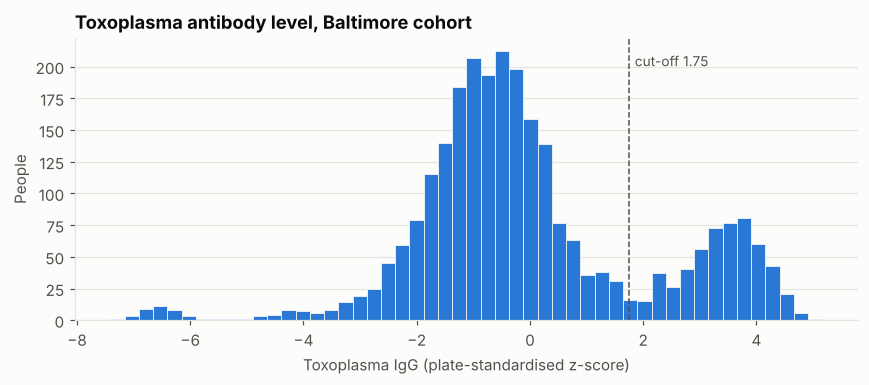

In [2]:
import pandas as pd
raw = pd.read_csv(os.path.join('data', 'external', 'johns_hopkins_baltimore', 'pone.0116696.s001.txt'), sep=None, engine='python')
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(raw['toxoigg_z_r1'], bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(1.75, color=INK_2, ls='--', lw=1)
ax.text(1.85, ax.get_ylim()[1] * 0.9, 'cut-off 1.75', color=INK_2, fontsize=9)
ax.set_xlabel('Toxoplasma IgG (plate-standardised z-score)'); ax.set_ylabel('People')
ax.set_title('Toxoplasma antibody level, Baltimore cohort')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [3]:
SETS = {'age + sex + diagnosis': ['age', 'male', 'schizophrenia_or_bipolar'],
        '+ CMV, HSV-1, HHV-6, gliadin antibodies, CRP': list(X.columns)}
rows = []
for s, cols in SETS.items():
    for m in ev.MODELS:
        a = ev.run(s, X[cols], y, m)[2]
        rows.append({'features': s, 'model': m, 'CV AUC': a.mean(), 'low': np.percentile(a, 2.5), 'high': np.percentile(a, 97.5)})
jh = pd.DataFrame(rows)
display(jh.pivot(index='features', columns='model', values='CV AUC').round(3))

model,LogReg,RandomForest,XGBoost
features,,,
"+ CMV, HSV-1, HHV-6, gliadin antibodies, CRP",0.709,0.682,0.692
age + sex + diagnosis,0.703,0.639,0.688


## 2. All US results side by side

,US dataset,questions on cats/meat/water,ROC-AUC
0,"NHANES 2009-2014, final model (toxo_max_score....",no,0.740
1,"NHANES 2013-2014, all 5,310 variables",no,0.721
2,"NHANES III 1988-1994, + direct exposure questions",yes,0.702
3,"Johns Hopkins Baltimore, + other antibodies",no,0.709


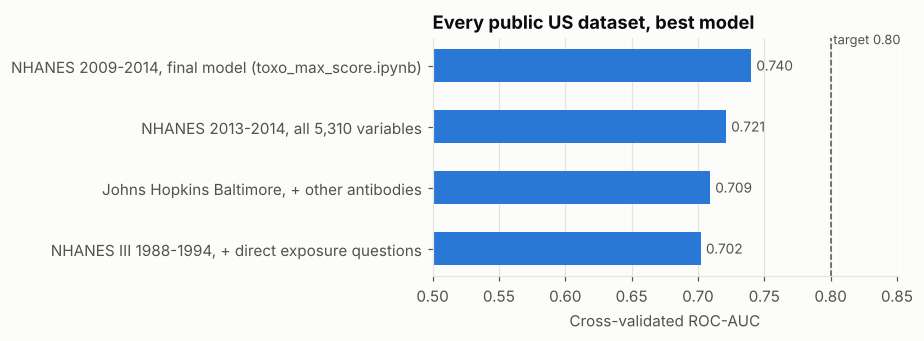

In [4]:
best_jh = jh.groupby('features')['CV AUC'].max()
summary = pd.DataFrame([
    {'US dataset': 'NHANES 2009-2014, final model (toxo_max_score.ipynb)', 'questions on cats/meat/water': 'no', 'ROC-AUC': 0.740},
    {'US dataset': 'NHANES 2013-2014, all 5,310 variables', 'questions on cats/meat/water': 'no', 'ROC-AUC': 0.721},
    {'US dataset': 'NHANES III 1988-1994, + direct exposure questions', 'questions on cats/meat/water': 'yes', 'ROC-AUC': 0.702},
    {'US dataset': 'Johns Hopkins Baltimore, + other antibodies', 'questions on cats/meat/water': 'no',
     'ROC-AUC': round(best_jh.max(), 3)},
])
display(summary)

fig, ax = plt.subplots(figsize=(8.5, 3.2))
s = summary.sort_values('ROC-AUC')
ax.barh(s['US dataset'], s['ROC-AUC'], color=BLUE, height=0.55)
for yv, v in enumerate(s['ROC-AUC']):
    ax.text(v + 0.004, yv, f'{v:.3f}', va='center', fontsize=9, color=INK_2)
ax.axvline(0.8, color=INK_2, ls='--', lw=1)
ax.text(0.802, 3.35, 'target 0.80', color=INK_2, fontsize=8.5)
ax.set_xlim(0.5, 0.85)
ax.set_xlabel('Cross-validated ROC-AUC')
ax.set_title('Every public US dataset, best model')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## What this means
- **Every public US dataset tops out at 0.70-0.74.** Three different US populations (national survey 1988-94, national survey 2009-14,
  Baltimore cohort) and every feature type tried (demographics, 5,310 NHANES variables, cat/meat/garden questions, antibodies to
  other infections) land in the same place.
- **0.80 is not reachable with public US data.** The non-US datasets that did reach 0.80 (`toxo_external_datasets.ipynb`) were
  high-exposure settings where cat contact, undercooked meat and unboiled water are common and vary between people. In the US, prevalence
  is low (15-19% of adults in NHANES 2009-2014) and most infections are old, so the same questions carry less signal (NHANES III shows this directly).
- **For the paper:** report the NHANES model (0.74) as the US result, state that it is the ceiling across all public US data, and
  explain why with this evidence.
- **Routes to more US data** (not public; need an application or contact with the authors): the CDC multicenter case-control
  study of recently infected US patients (Jones et al. 2009, raw oysters, rare meat, goat milk), the San Antonio Family Heart Study serology
  (Mexican Americans, 13 pathogens), and the full Johns Hopkins Baltimore cohort records (the public file has no exposure questions).